# Marmousi01 — true velocity model: read & view

First step of the pre-refactor FWI-loop test: load and inspect the
Marmousi01 true velocity model — `float32`, shape 128×256 (a downsampled
Marmousi grid: 128 depth samples × 256 lateral samples).

The file lives in the sibling benchmark project
(`projetos/Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy`); this
notebook stays in `ls-fwi` and only READS it.

Reference: the classic Marmousi1 model spans ~1500–5500 m/s
(water layer ~1500 m/s at the top).

In [1]:
import numpy as np
from pathlib import Path

CANDIDATES = [
    Path("../../Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy"),   # repo root
    Path("../../../Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy"),  # notebooks/
    Path("/tgdesenv/src/proj0/ntbs/doutorado/5semestre.2024.2/estudo.orientado/"
         "projetos/Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy"),  # host
    Path("/tgdesenv/doutorado/5semestre.2024.2/estudo.orientado/"
         "projetos/Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy"),  # container
]
MARM = next(c for c in CANDIDATES if c.exists())
m = np.load(MARM)

print(f"file : {MARM}")
print(f"shape: {m.shape}  dtype: {m.dtype}")
print(f"range: {m.min():.1f} .. {m.max():.1f}")
print(f"mean : {m.mean():.1f}")

file : ../../Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy
shape: (128, 256)  dtype: float32
range: 1500.0 .. 4699.9
mean : 2682.2


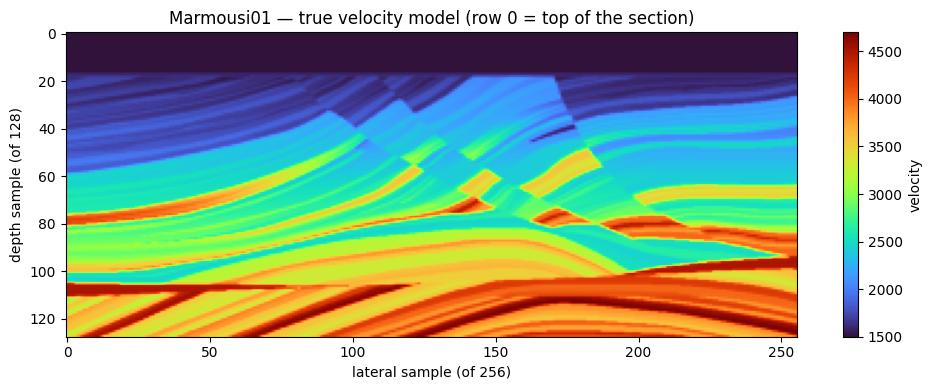

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(m, cmap="turbo", aspect="auto", origin="upper")
ax.set_xlabel("lateral sample (of 256)")
ax.set_ylabel("depth sample (of 128)")
ax.set_title("Marmousi01 — true velocity model (row 0 = top of the section)")
fig.colorbar(im, ax=ax, label="velocity")
plt.tight_layout()
plt.show()

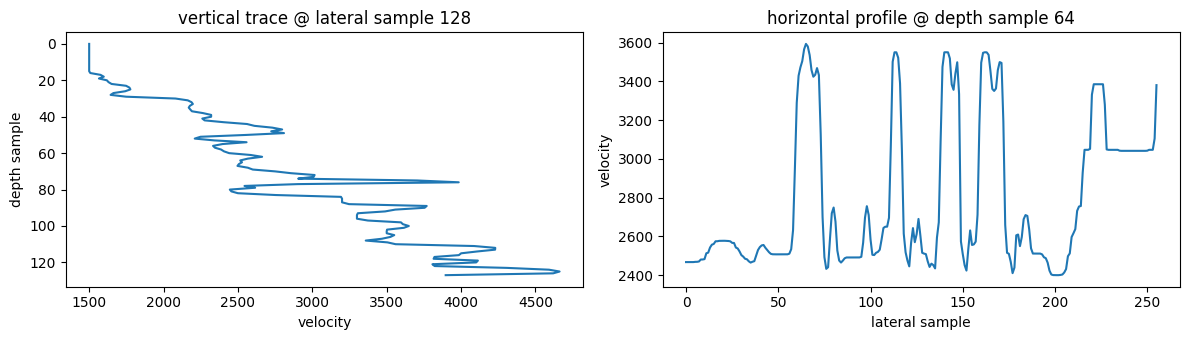

In [3]:
# quick profiles: one velocity trace (vertical) and one horizontal
# layer profile — useful sanity checks before wiring an FWI loop
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 3.5))
axL.plot(m[:, m.shape[1] // 2], np.arange(m.shape[0]))
axL.invert_yaxis()
axL.set_xlabel("velocity")
axL.set_ylabel("depth sample")
axL.set_title(f"vertical trace @ lateral sample {m.shape[1] // 2}")
axR.plot(m[m.shape[0] // 2, :])
axR.set_xlabel("lateral sample")
axR.set_ylabel("velocity")
axR.set_title(f"horizontal profile @ depth sample {m.shape[0] // 2}")
plt.tight_layout()
plt.show()

## From Marmousi to the pipeline's model grid

The AE's generator works on **(672, 800)**: `Utils.find_size(depth=5)`
takes the raw (680, 800) models down to the largest sizes divisible by
2⁵ (the decoder's 5 upsampling levels), and the latent grid
(1, 512, 21, 25) is exactly 672/32 × 800/32.

The Marmousi file (128×256) is *smaller* in both dimensions, so this is
not a crop — it is a **resample** (bilinear upscale) to 672×800,
followed by the campaign's normalization.

**Normalization** (from `src/preprocessing/pipeline.py`, exactly as the
apps invoke it): `BatchAbsMaxScaler` is fitted on the TRAIN split's true
models — `absmax = max(|X|, axis=(0,1))` over the (900, 680, 800) stack,
i.e. one abs-max **per lateral column** — and every model (train and
test) is divided by it. The files are raw m/s; after scaling, velocities
become fractions of their column's train-set maximum (the context
figures' 0.4–0.9 colorbars). The Marmousi gets the same treatment:
resample FIRST (so the columns align), then divide by the same
per-column absmax.

resampled: (672, 800), range 1500.0..4699.0 m/s


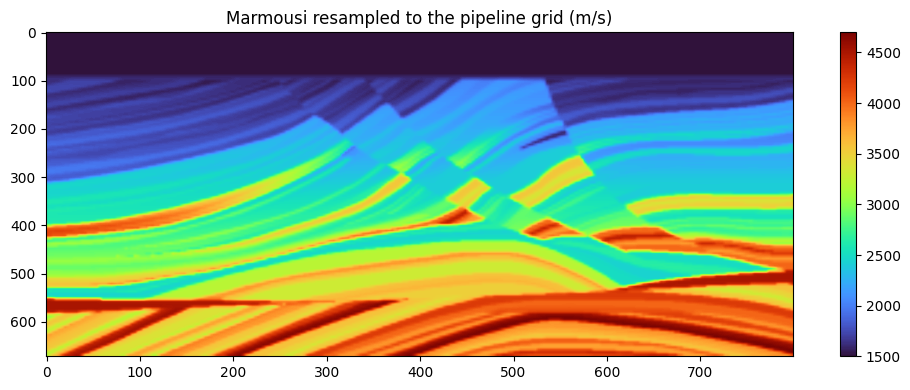

In [4]:
# resample 128x256 -> (672, 800), still in m/s
import torch

NZ, NX = 672, 800                     # nz_cut x nx_cut (find_size depth=5)
m_up = torch.nn.functional.interpolate(
    torch.from_numpy(m[None, None].astype(np.float32)),
    size=(NZ, NX), mode="bilinear", align_corners=False)[0, 0].numpy()
print(f"resampled: {m_up.shape}, range {m_up.min():.1f}..{m_up.max():.1f} m/s")

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(m_up, cmap="turbo", aspect="auto")
ax.set_title("Marmousi resampled to the pipeline grid (m/s)")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

<2026-11-25 23:05:37> [ INFO ] FINDING OUT DATA FORMAT

<2026-11-25 23:05:37> [ INFO ] 	Filename: /gemini/tg/ntbs/doutorado/5semestre/estudo.orientado/deeptomograph_data/data_new_and_bigger/./input_suave_1.npy

<2026-11-25 23:05:37> [ INFO ] 	File shape: (680, 800, 15)

<2026-11-25 23:05:37> [ INFO ] 	Target z_len (newer dataset): 680

---------------------------------------------------
<2026-11-25 23:05:37> [ NEW DATA ] Building Deep Tomography models...
---------------------------------------------------
---------------------------------------------------
---------------------------------------------------
---------------------------------------------------
<2026-11-25 23:05:37> Spliting samples into train and test!
---------------------------------------------------
<2026-11-25 23:05:37> [ INFO ] Total nmb of samples: 1000

<2026-11-25 23:05:37> [ INFO ] Percentage of test samples: 10.0%

<2026-11-25 23:05:37> [ DEBUG ] set1_indexes.shape[0]+set2_indexes.shape[0] == nsamples        

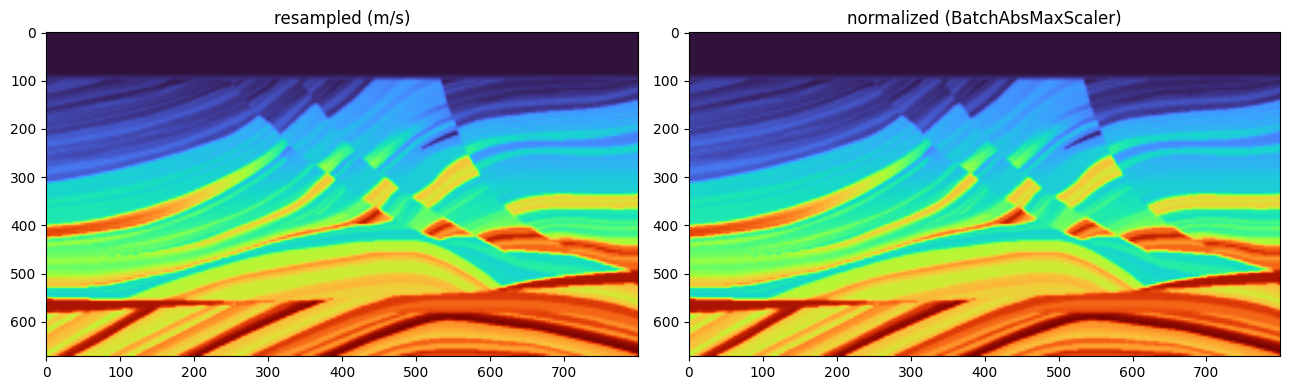

In [5]:
# the campaign's normalization: BatchAbsMaxScaler fitted on the TRAIN
# split (src/preprocessing/pipeline.py) — one abs-max per lateral column
from src.apps.global_vars import load_data_and_models

(data_basedir, dirs, train_data, test_data,
 train_models, test_models, train_indexes, test_indexes, newer) = \
    load_data_and_models(data='deep', data_type='deep', data_resolution='high',
                         data_max_samples=None, test_perc=0.1, seed=79)

raw_train = train_models.get_true_models().get_models()   # (900, 680, 800), raw m/s
absmax = np.max(np.abs(raw_train), axis=(0, 1))           # (800,) per lateral column
print(f"train true models: {raw_train.shape}, range "
      f"{raw_train.min():.1f}..{raw_train.max():.1f} m/s")
print(f"absmax per column: {absmax.shape}, "
      f"range {absmax.min():.1f}..{absmax.max():.1f} m/s")

m_ds = m_up / absmax                                      # broadcast over (672, 800)
print(f"normalized Marmousi: range {m_ds.min():.3f}..{m_ds.max():.3f} "
      "(context figures show ~0.4..0.9)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.imshow(m_up, cmap="turbo", aspect="auto"); ax1.set_title("resampled (m/s)")
ax2.imshow(m_ds, cmap="turbo", aspect="auto"); ax2.set_title("normalized (BatchAbsMaxScaler)")
plt.tight_layout()
plt.show()

## Invert: latent optimization against the Marmousi target

Reuses the campaign machinery exactly as `task_processing.py` does:
`EncoderDecoder` loaded from the refit checkpoint via skorch
(`load_params`), split into Encoder + Generator, then
`SkorchGeneratorInversionBuilder` with the campaign's best config:
**trained init** — the starting latent is `Encoder(x)` of train-split
position 10 (dataset example 182), the SAME initial latent as every
`trained` run of the campaign (hence the identical first column in the
exploratory traverse figure). Sequence per the source: `initialize()` →
`set_latent(...)` → `partial_fit(...)` — never re-initialize after
setting the latent. lr=0.1, 1000 epochs; the Marmousi target is the
resampled, normalized model from the previous cells. (Per the
reachability result, `zeros`/`random` reach the same floor — the
zeros variant is kept in the control cells below.)

In [ ]:
import sys, json, re, ast, urllib.request
import torch.nn as nn
from pathlib import Path

REPO = Path("..").resolve() if (Path("..") / "src").exists() else Path(".").resolve()
sys.path.insert(0, str(REPO))

import ml_collections
from src.processing.ml_models import EncoderDecoder
from src.processing.ml_models_builder import (ScoredSkorchModel,
    SkorchEncoderModelBuilder, SkorchGeneratorModelBuilder,
    SkorchGeneratorInversionBuilder)
from src.experiment_tracking.mlflow_utils import MLFlowUtils

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# --- campaign wiring, reconstructed from the runs' logged params ---
BEST_RUN = "aa821c27efd64fdbbe99012a8ebc96ca"   # best inversion run
REFIT_RUN = "9247757e7e0f49459ee4fe8e897fcd14"  # encdec 5x5, seed 79
MLFLOW = "http://gr14sm02.ep.petrobras.com.br:31947/api/2.0/mlflow"

def run_params(run_id):
    with urllib.request.urlopen(f"{MLFLOW}/runs/get?run_id={run_id}",
                                timeout=30) as r:
        data = json.loads(r.read().decode())["run"]["data"]
    return {x["key"]: x["value"] for x in data["params"]}

inv_params = run_params(BEST_RUN)
refit_params = run_params(REFIT_RUN)

# checkpoint: the exact file the best run loaded (logged in its grid)
ckpt = re.search(r"'weights_files': \['([^']+)'\]",
                 inv_params["inference_grid"]).group(1)
print("checkpoint:", ckpt)

# module kwargs: the refit's logged module__* values, typed via
# literal_eval (strings like '5,5' -> (5, 5), '0.2' -> 0.2, 'False' -> False;
# non-literals like unembed_type='paper' stay as strings)
module_kwargs = {}
for k, v in refit_params.items():
    if not k.startswith("module__") or k == "module__attention_config":
        continue
    try:
        module_kwargs[k] = ast.literal_eval(v)
    except (ValueError, SyntaxError):
        module_kwargs[k] = v

# attention config: rebuilt exactly as global_vars does — ConfigDict over
# string_to_dict + the patches override. Note module__use_transformers is
# False for this refit, so the module never touches the attention path.
attention_config = ml_collections.ConfigDict(
    MLFlowUtils.string_to_dict(refit_params["module__attention_config"]))
attention_config.patches = ml_collections.ConfigDict({"size": (1, 1)})
module_kwargs["module__attention_config"] = attention_config

print("module kwargs:")
for k, v in sorted(module_kwargs.items()):
    print(f"   {k} = {v}")

autoencoder = ScoredSkorchModel(
    module=EncoderDecoder, device=device, seed=79, **module_kwargs)
autoencoder.initialize()
autoencoder.load_params(f_params=ckpt)

encoder = SkorchEncoderModelBuilder().build(
    autoencoder=autoencoder.module_, device=device)
encoder.initialize()
generator = SkorchGeneratorModelBuilder().build(
    autoencoder=autoencoder.module_, device=device)
generator.initialize()

# the campaign's forward logs latent.mean() every step — silence it here
from src.processing import ml_models as _mlm
_mlm.log.info = lambda *a, **k: None

inversion = SkorchGeneratorInversionBuilder().build(
    generator=generator.module_, latent_shape=(1, 512, 21, 25),
    latent_init="trained", seed=79,
    max_epochs=1000, device=device, lr=0.1)   # best campaign config
inversion.initialize()

# trained init: the SAME starting latent as the campaign's trained
# runs — Encoder(x) of train-split position 10 (dataset example
# 182), normalized with the train absmax and cropped like crop_data
x_init = ((raw_train[10] / absmax)[:672, :800])[None, None].astype(np.float32)
z0 = encoder.predict(torch.from_numpy(x_init).to(device))
inversion.module_.set_latent(z0)
print("trained latent set from train example", int(train_indexes[10]))

y = torch.from_numpy(m_ds[None, None].astype(np.float32)).to(device)
x = torch.zeros_like(y)                      # X is ignored by forward
inversion.partial_fit(x, y)
print("done — final train_loss:", inversion.history[-1]["train_loss"])


In [ ]:
# results — loss curve (with the pack's 95%/99% marks) and the recovery
losses = [h["train_loss"] for h in inversion.history]
final = losses[-1]
step95 = next(i for i, v in enumerate(losses) if v <= 1.05 * final)
step99 = next(i for i, v in enumerate(losses) if v <= 1.01 * final)
print(f"final MSE {final:.5f} | 95% at epoch {step95 + 1}, "
      f"99% at epoch {step99 + 1} (of {len(losses)})")

z = inversion.module_.latent.detach()
rec = generator.module_(z)[0, 0].detach().cpu().numpy()
tgt = y[0, 0].cpu().numpy()

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 4))
axL.plot(losses)
axL.axvline(step95, ls="--", lw=1, alpha=0.6)
axL.axvline(step99, ls=":", lw=1, alpha=0.6)
axL.set_yscale("log")
axL.set_xlabel("epoch (1 backpropagation step each)")
axL.set_ylabel("inversion loss (model-space MSE)")
axL.set_title("convergence — trained init, lr=0.1, 1000 epochs")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, img, ttl in zip(axes, [tgt, rec, tgt - rec],
                        ["target (Marmousi, dataset scale)",
                         "latent recovery (zeros init)",
                         "difference"]):
    ax.imshow(img, cmap="turbo", aspect="auto")
    ax.set_title(ttl, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## Control: the campaign's three targets, re-run in this notebook

The three test-set targets of the campaign (positions 1/10/20 →
dataset examples 476/696/5), inverted again with the same machinery
and config as the Marmousi run (zeros init, lr=0.1, 1000 epochs).

The advantage: these re-runs optimize against the generator in
**eval mode** (the `GeneratorInversion.train()` override pins it),
while the campaign's logged curves were produced with the generator
in **train mode** (dropout active — the +2.1% median gap between the
logged trajectories and the reported eval MSEs, flagged in
`DATA_DICTIONARY.md`). Same targets, same config, same init — the
only difference is the mode fix.

In [10]:
# re-run the campaign's three targets (eval-mode generator)
test_true = test_models.get_true_models().get_models()  # (100, 680, 800) raw m/s
re_runs = {}
for mi in (1, 10, 20):
    t = (test_true[mi] / absmax)[:672, :800]   # train-fitted scaler, then crop
    y_t = torch.from_numpy(t[None, None].astype(np.float32)).to(device)
    inv = SkorchGeneratorInversionBuilder().build(
        generator=generator.module_, latent_shape=(1, 512, 21, 25),
        latent_init="zeros", seed=79,
        max_epochs=1000, device=device, lr=0.1)
    inv.initialize()
    inv.partial_fit(torch.zeros_like(y_t), y_t)
    losses_t = [h["train_loss"] for h in inv.history]
    final_t = losses_t[-1]
    s95 = next(i for i, v in enumerate(losses_t) if v <= 1.05 * final_t)
    s99 = next(i for i, v in enumerate(losses_t) if v <= 1.01 * final_t)
    ex_id = int(test_indexes[mi])
    re_runs[mi] = {"losses": losses_t, "ex_id": ex_id}
    print(f"pos {mi} (example {ex_id}): final MSE {final_t:.5f} | "
          f"95% at epoch {s95 + 1}, 99% at epoch {s99 + 1} (of {len(losses_t)})")

---------------------------------------------------
<2026-11-25 23:23:27> GeneratorInversion Constructor!!!
---------------------------------------------------
pos 1 (example 476): final MSE 0.00027 | 95% at epoch 579, 99% at epoch 895 (of 1000)
---------------------------------------------------
<2026-11-25 23:23:39> GeneratorInversion Constructor!!!
---------------------------------------------------
pos 10 (example 696): final MSE 0.00031 | 95% at epoch 679, 99% at epoch 862 (of 1000)
---------------------------------------------------
<2026-11-25 23:23:51> GeneratorInversion Constructor!!!
---------------------------------------------------
pos 20 (example 5): final MSE 0.00011 | 95% at epoch 511, 99% at epoch 855 (of 1000)


In [ ]:
# comparison — solid: notebook re-runs (zeros, EVAL-mode generator);
# dashed: the campaign's zeros@0.1@1000ep logs (train mode) — isolates
# the eval-mode fix; dotted: the campaign's BEST run (trained init,
# same config, train mode) — the pack's reference, adds the init effect;
# black: the Marmousi run. All in absolute model-space MSE.
import pandas as pd
from matplotlib.lines import Line2D

DATA = Path("data") if Path("data/runs.csv").exists() else Path("notebooks/data")
runs = pd.read_csv(DATA / "runs.csv", dtype={"refit_short": str})

def campaign_run(init):
    c = runs[(runs["refit_short"] == "9247757e") & (runs["latent_init"] == init)
             & (runs["lr"] == 0.1) & (runs["max_epochs"] == 1000)]
    assert len(c) == 1, f"expected exactly one {init}@0.1@1000ep run"
    return c.iloc[0]["run_id"]

camp_ids = {"zeros": campaign_run("zeros"), "best": campaign_run("trained")}
hpe = pd.read_csv(DATA / "train_loss_per_example.csv", dtype={"refit_short": str})
camp_curves = {name: hpe[hpe["run_id"] == rid] for name, rid in camp_ids.items()}
pm = pd.read_csv(DATA / "inversion_per_model.csv", dtype={"refit_short": str})
camp_mse = {name: pm[pm["run_id"] == rid].set_index("model_idx")["mse"]
            for name, rid in camp_ids.items()}

fig, ax = plt.subplots(figsize=(11.5, 5))
colors = {1: "C0", 10: "C1", 20: "C2"}
styles = {"zeros": "--", "best": ":"}
for name in ("zeros", "best"):
    for mi in (1, 10, 20):
        g = camp_curves[name][camp_curves[name]["model_idx"] == mi].sort_values("step")
        ax.plot(g["step"], g["value"], ls=styles[name], lw=1,
                color=colors[mi], alpha=0.7)
for mi in (1, 10, 20):
    ax.plot(range(1, len(re_runs[mi]["losses"]) + 1), re_runs[mi]["losses"],
            ls="-", lw=1.5, color=colors[mi],
            label=f"pos {mi} (example {re_runs[mi]['ex_id']})")
ax.plot(range(1, len(losses) + 1), losses, color="k", lw=1.8,
        label="Marmousi (trained init)")
ax.set_yscale("log")
ax.set_xlabel("epoch (1 backpropagation step each)")
ax.set_ylabel("inversion loss (model-space MSE)")
ax.set_title("notebook re-runs (zeros, eval mode, solid) vs campaign zeros "
             "(train, dashed) vs campaign best (trained, dotted) + Marmousi")
handles, _ = ax.get_legend_handles_labels()
handles += [Line2D([], [], color="k", ls="--", lw=1,
                   label="campaign zeros (train mode)"),
            Line2D([], [], color="k", ls=":", lw=1,
                   label="campaign best / trained (train mode)")]
ax.legend(handles=handles, fontsize=8)
plt.tight_layout()
plt.show()

hdr = (f"{'target':26s} {'notebook':>10s} {'z.traj':>10s} {'z.eval':>10s}"
       f" {'b.traj':>10s} {'b.eval':>10s}")
print(hdr)
print(f"{'Marmousi (resampled)':26s} {final:10.5f} {'—':>10s} {'—':>10s}"
      f" {'—':>10s} {'—':>10s}")
for mi in (1, 10, 20):
    rows = {}
    for name in ("zeros", "best"):
        g = camp_curves[name][camp_curves[name]["model_idx"] == mi].sort_values("step")
        rows[name] = (float(g["value"].iloc[-1]), float(camp_mse[name].loc[mi]))
    nf = re_runs[mi]["losses"][-1]
    print(f"pos {mi} (ex {re_runs[mi]['ex_id']}){'':<9} {nf:10.5f}"
          f" {rows['zeros'][0]:10.5f} {rows['zeros'][1]:10.5f}"
          f" {rows['best'][0]:10.5f} {rows['best'][1]:10.5f}")
print("z = campaign zeros init (train mode) · b = campaign best run,"
      " trained init (train mode) · traj = logged trajectory end ·"
      " eval = reported eval MSE")
